<a href="https://colab.research.google.com/github/CChinmayi18/red_black_tree_dsa_/blob/main/ml5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Activation: relu
Loss: binary_crossentropy
Optimizer: adam
Test Accuracy: 95.61 %
Test Loss: 0.0909

Activation: relu
Loss: binary_crossentropy
Optimizer: sgd
Test Accuracy: 93.86 %
Test Loss: 0.1492

Activation: relu
Loss: mean_squared_error
Optimizer: adam
Test Accuracy: 96.49 %
Test Loss: 0.0271

Activation: relu
Loss: mean_squared_error
Optimizer: sgd
Test Accuracy: 91.23 %
Test Loss: 0.0733

Activation: LeakyReLU
Loss: binary_crossentropy
Optimizer: adam
Test Accuracy: 96.49 %
Test Loss: 0.0885

Activation: LeakyReLU
Loss: binary_crossentropy
Optimizer: sgd
Test Accuracy: 93.86 %
Test Loss: 0.1477

Activation: LeakyReLU
Loss: mean_squared_error
Optimizer: adam
Test Accuracy: 95.61 %
Test Loss: 0.026

Activation: LeakyReLU
Loss: mean_squared_error
Optimizer: sgd
Test Accuracy: 91.23 %
Test Loss: 0.0714

Activation: gelu
Loss: binary_crossentropy
Optimizer: adam
Test Accuracy: 96.49 %
Test Loss: 0.0932

Activation: gelu
Loss: binary_crossentropy
Optimizer: sgd
Test Accuracy: 92.98 

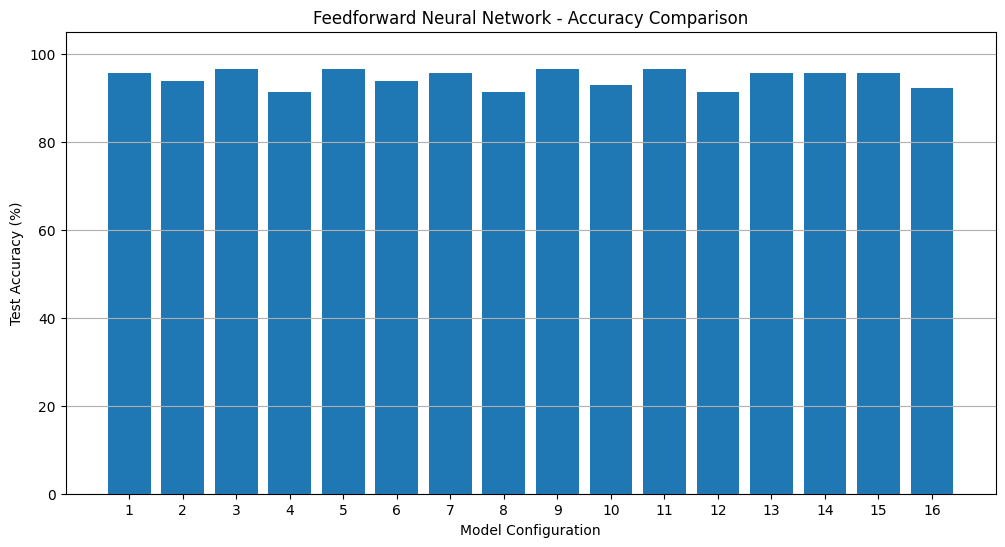


PROGRAM COMPLETED SUCCESSFULLY


In [1]:

# EXPERIMENT: BUILDING AND TRAINING FEEDFORWARD NEURAL NETWORKS

# Step 1: Import Required Libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, LeakyReLU
from tensorflow.keras.utils import to_categorical

# Step 2: Load Dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Step 3: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Normalize Data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 5: Define Model Creation Function
def create_model(activation, optimizer, loss):

    model = Sequential()

    model.add(Input(shape=(X_train.shape[1],)))

    if activation == "LeakyReLU":
        model.add(Dense(32))
        model.add(LeakyReLU(negative_slope=0.1))
        model.add(Dense(16, activation="relu"))
    else:
        model.add(Dense(32, activation=activation))
        model.add(Dense(16, activation=activation))

    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=["accuracy"]
    )

    return model

# Step 6: Define Activation Functions
activations = ["relu", "LeakyReLU", "gelu", "tanh"]

# Step 7: Define Loss Functions and Optimizers
loss_functions = ["binary_crossentropy", "mean_squared_error"]
optimizers = ["adam", "sgd"]

# Step 8: Train and Evaluate Models
results = []

for activation in activations:

    for loss in loss_functions:

        for optimizer in optimizers:

            print("\n===================================")
            print("Activation:", activation)
            print("Loss:", loss)
            print("Optimizer:", optimizer)

            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(42)

            model = create_model(activation, optimizer, loss)

            history = model.fit(
                X_train, y_train,
                epochs=20,
                batch_size=16,
                validation_split=0.2,
                verbose=0
            )

            test_loss, test_accuracy = model.evaluate(
                X_test, y_test, verbose=0
            )

            print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
            print("Test Loss:", round(test_loss, 4))

            results.append({
                "Activation": activation,
                "Loss Function": loss,
                "Optimizer": optimizer,
                "Accuracy": round(test_accuracy * 100, 2),
                "Test Loss": round(test_loss, 4)
            })

# Step 9: Display Performance Comparison
results_df = pd.DataFrame(results)

print("\n========== PERFORMANCE COMPARISON ==========")
print(results_df.to_string(index=False))

# Step 10: Find Best Model
best_model = results_df.loc[results_df["Accuracy"].idxmax()]

print("\n========== BEST MODEL ==========")
print(best_model)

# Step 11: Plot Accuracy Comparison
plt.figure(figsize=(12, 6))

plt.bar(
    range(len(results_df)),
    results_df["Accuracy"]
)

plt.xlabel("Model Configuration")
plt.ylabel("Test Accuracy (%)")
plt.title("Feedforward Neural Network - Accuracy Comparison")
plt.xticks(range(len(results_df)), range(1, len(results_df) + 1))
plt.ylim(0, 105)
plt.grid(axis="y")

plt.show()

# Step 12: Display Final Result
print("\nPROGRAM COMPLETED SUCCESSFULLY")
